In [204]:
# Regression lineaire, Random forest, XGBoost, LightGBM, CatBoost, ExtraTrees​, PLS Regressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
import hydroeval as hd
from sklearn.base import clone

#plt.style.use("dark_background")

In [205]:
rl=LinearRegression()
rd=RandomForestRegressor()
xgb=XGBRegressor()
lgbm=LGBMRegressor()
cbc=CatBoostRegressor()
psl=PLSRegression()
extr=ExtraTreesRegressor()
liste_mode=[rl,rd,xgb,lgbm,cbc,psl,extr]

In [206]:
data=pd.read_excel("Data//DonneePreModel.xlsx")
data=data.dropna()
data.head()

,Date,Pluie,Debit,Debit-j+1,Debit-j+2,Debit-j+3,Debit-j+4,Debit-j+5,Cum_Pluie_15,Cum_Pluie_30,...,Debit-j-2,Debit-j-3,Debit-j-4,Debit-j-5,Cum_Pluie_110,Cum_Pluie_130,Cum_Pluie_150,Cum_Pluie_170,Cum_Pluie_180,Cum_Pluie_200
5,1992-01-06,0.0,16.610001,16.430000,16.200001,16.129999,15.90,15.66,0.0,0.0,...,17.000000,17.150000,17.280001,17.280001,0.0,0.0,0.0,0.0,0.0,0.0
6,1992-01-07,0.0,16.430000,16.200001,16.129999,15.900000,15.66,15.61,0.0,0.0,...,16.889999,17.000000,17.150000,17.280001,0.0,0.0,0.0,0.0,0.0,0.0
7,1992-01-08,0.0,16.200001,16.129999,15.900000,15.660000,15.61,15.48,0.0,0.0,...,16.610001,16.889999,17.000000,17.150000,0.0,0.0,0.0,0.0,0.0,0.0
8,1992-01-09,0.0,16.129999,15.900000,15.660000,15.610000,15.48,15.33,0.0,0.0,...,16.430000,16.610001,16.889999,17.000000,0.0,0.0,0.0,0.0,0.0,0.0
9,1992-01-10,0.0,15.900000,15.660000,15.610000,15.480000,15.33,15.21,0.0,0.0,...,16.200001,16.430000,16.610001,16.889999,0.0,0.0,0.0,0.0,0.0,0.0


In [207]:
cible=["Debit-j+1","Debit-j+2","Debit-j+3"]
data["Annee"]=data.Date.dt.year
data["Mois"]=data.Date.dt.month
data["Jour"]=data.Date.dt.day
data=data.drop(["Date","Debit-j+4","Debit-j+5"],axis=1)
train=data[data.Annee<=2014]
test=data[(2014<data.Annee) & (data.Annee<=2019)]
#vald=data[(2019<data.Annee)]
X_train=train.drop(cible,axis=1)
X_test=test.drop(cible,axis=1)
y_train=train[cible]
y_test=test[cible]
X_train=X_train.drop("Annee",axis=1)
X_test=X_test.drop("Annee",axis=1)

Exog=train["Pluie"]
X=train["Debit"]

In [208]:
resultats={"Model":[],"Jour":[],"MAE":[],"RMSE":[],"kge":[],"r":[],"Alpha":[],"beta":[]}
def entrainement(model):
    print(model.__class__.__name__)
    for cib in cible:
        mod=clone(model)
        y_true=y_test[cib]
        y_true = np.asarray(y_true).ravel()
        mod.fit(X_train,y_train[cib])
        predi=mod.predict(X_test)
        predi = np.asarray(predi).ravel()
        mae=mean_absolute_error(predi,y_true)
        rmse=np.sqrt(mean_squared_error(predi,y_true))
        kge, r, alpha, beta = hd.evaluator(hd.kge,predi,y_true)
        resultats["Model"].append(model.__class__.__name__)
        resultats["Jour"].append(cib)
        resultats["MAE"].append(mae)
        resultats["RMSE"].append(rmse)
        resultats["kge"].append(kge)
        resultats["r"].append(r)
        resultats["Alpha"].append(alpha)
        resultats["beta"].append(beta)


"""for m in liste_mode:
    entrainement(m)"""


'for m in liste_mode:\n    entrainement(m)'

In [209]:
"""resultats=pd.DataFrame(resultats).sort_values(by="MAE")"""

'resultats=pd.DataFrame(resultats).sort_values(by="MAE")'

In [210]:
"""resultats.set_index("Model")"""

'resultats.set_index("Model")'

In [214]:
model1=LinearRegression()
model2=LinearRegression()
model3=LinearRegression()
scal=StandardScaler()
X_train_sc=scal.fit_transform(X_train)
X_test_sc=scal.transform(X_test)

model1.fit(X_train_sc,y_train["Debit-j+1"])
predic1=model1.predict(X_test_sc)

model2.fit(X_train_sc,y_train["Debit-j+2"])
predic2=model2.predict(X_test_sc)

model3.fit(X_train_sc,y_train["Debit-j+3"])
predic3=model3.predict(X_test_sc)

MAE1=mean_absolute_error(predic1,y_test["Debit-j+1"])
RMSE1=np.sqrt(mean_squared_error(predic1,y_test["Debit-j+1"]))

MAE2=mean_absolute_error(predic2,y_test["Debit-j+2"])
RMSE2=np.sqrt(mean_squared_error(predic2,y_test["Debit-j+2"]))

MAE3=mean_absolute_error(predic3,y_test["Debit-j+3"])
RMSE3=np.sqrt(mean_squared_error(predic3,y_test["Debit-j+3"]))

print(f"MAE j+1 : {mean_absolute_error(predic1,y_test["Debit-j+1"])} \n RMSE : {np.sqrt(mean_squared_error(predic1,y_test["Debit-j+1"]))}")
print(f"MAE j+2 : {mean_absolute_error(predic2,y_test["Debit-j+2"])} \n RMSE : {np.sqrt(mean_squared_error(predic2,y_test["Debit-j+2"]))}")
print(f"MAE j+1 : {mean_absolute_error(predic3,y_test["Debit-j+3"])} \n RMSE : {np.sqrt(mean_squared_error(predic3,y_test["Debit-j+3"]))}")

# ---- Validation sur TOUTES les annees disponibles apres le test : entrainement du modele J+1 sur Train + Test ----
# On reconstruit une colonne Date a partir de Annee / Mois / Jour (year/month/day requis par pandas)
vald = data[(data.Annee == 2023) & (data.Mois.between(8, 11))].head(len(data[(data.Annee == 2023) & (data.Mois.between(8, 11))])-25).copy()  # 2023, Aout a Novembre
vald["Date"] = pd.to_datetime(dict(year=vald["Annee"], month=vald["Mois"], day=vald["Jour"]))
vald = vald.sort_values("Date")

X_val = vald.drop(cible + ["Date", "Annee"], axis=1)
y_val = vald[cible]
dates_val = vald["Date"]

X_full = pd.concat([X_train, X_test], axis=0)
y_full = pd.concat([y_train, y_test], axis=0)

scal_full = StandardScaler()
X_full_sc = scal_full.fit_transform(X_full)
X_val_sc = scal_full.transform(X_val)

model_j1_full = LinearRegression()
model_j1_full.fit(X_full_sc, y_full["Debit-j+1"])
predic_val_j1 = model_j1_full.predict(X_val_sc)

MAE_val = mean_absolute_error(predic_val_j1, y_val["Debit-j+1"])
RMSE_val = np.sqrt(mean_squared_error(predic_val_j1, y_val["Debit-j+1"]))
periode_label = f"{dates_val.min().strftime('%b %Y')} a {dates_val.max().strftime('%b %Y')}"
print(f"MAE J+1 (validation, {periode_label}) : {MAE_val:.2f} \n RMSE : {RMSE_val:.2f}")


MAE j+1 : 5.224209628349959 
 RMSE : 11.331633025436794
MAE j+2 : 11.23260758636218 
 RMSE : 22.574744183224936
MAE j+1 : 17.471732804458608 
 RMSE : 32.67494047674568
MAE J+1 (validation, Aug 2023 a Nov 2023) : 7.89 
 RMSE : 9.74


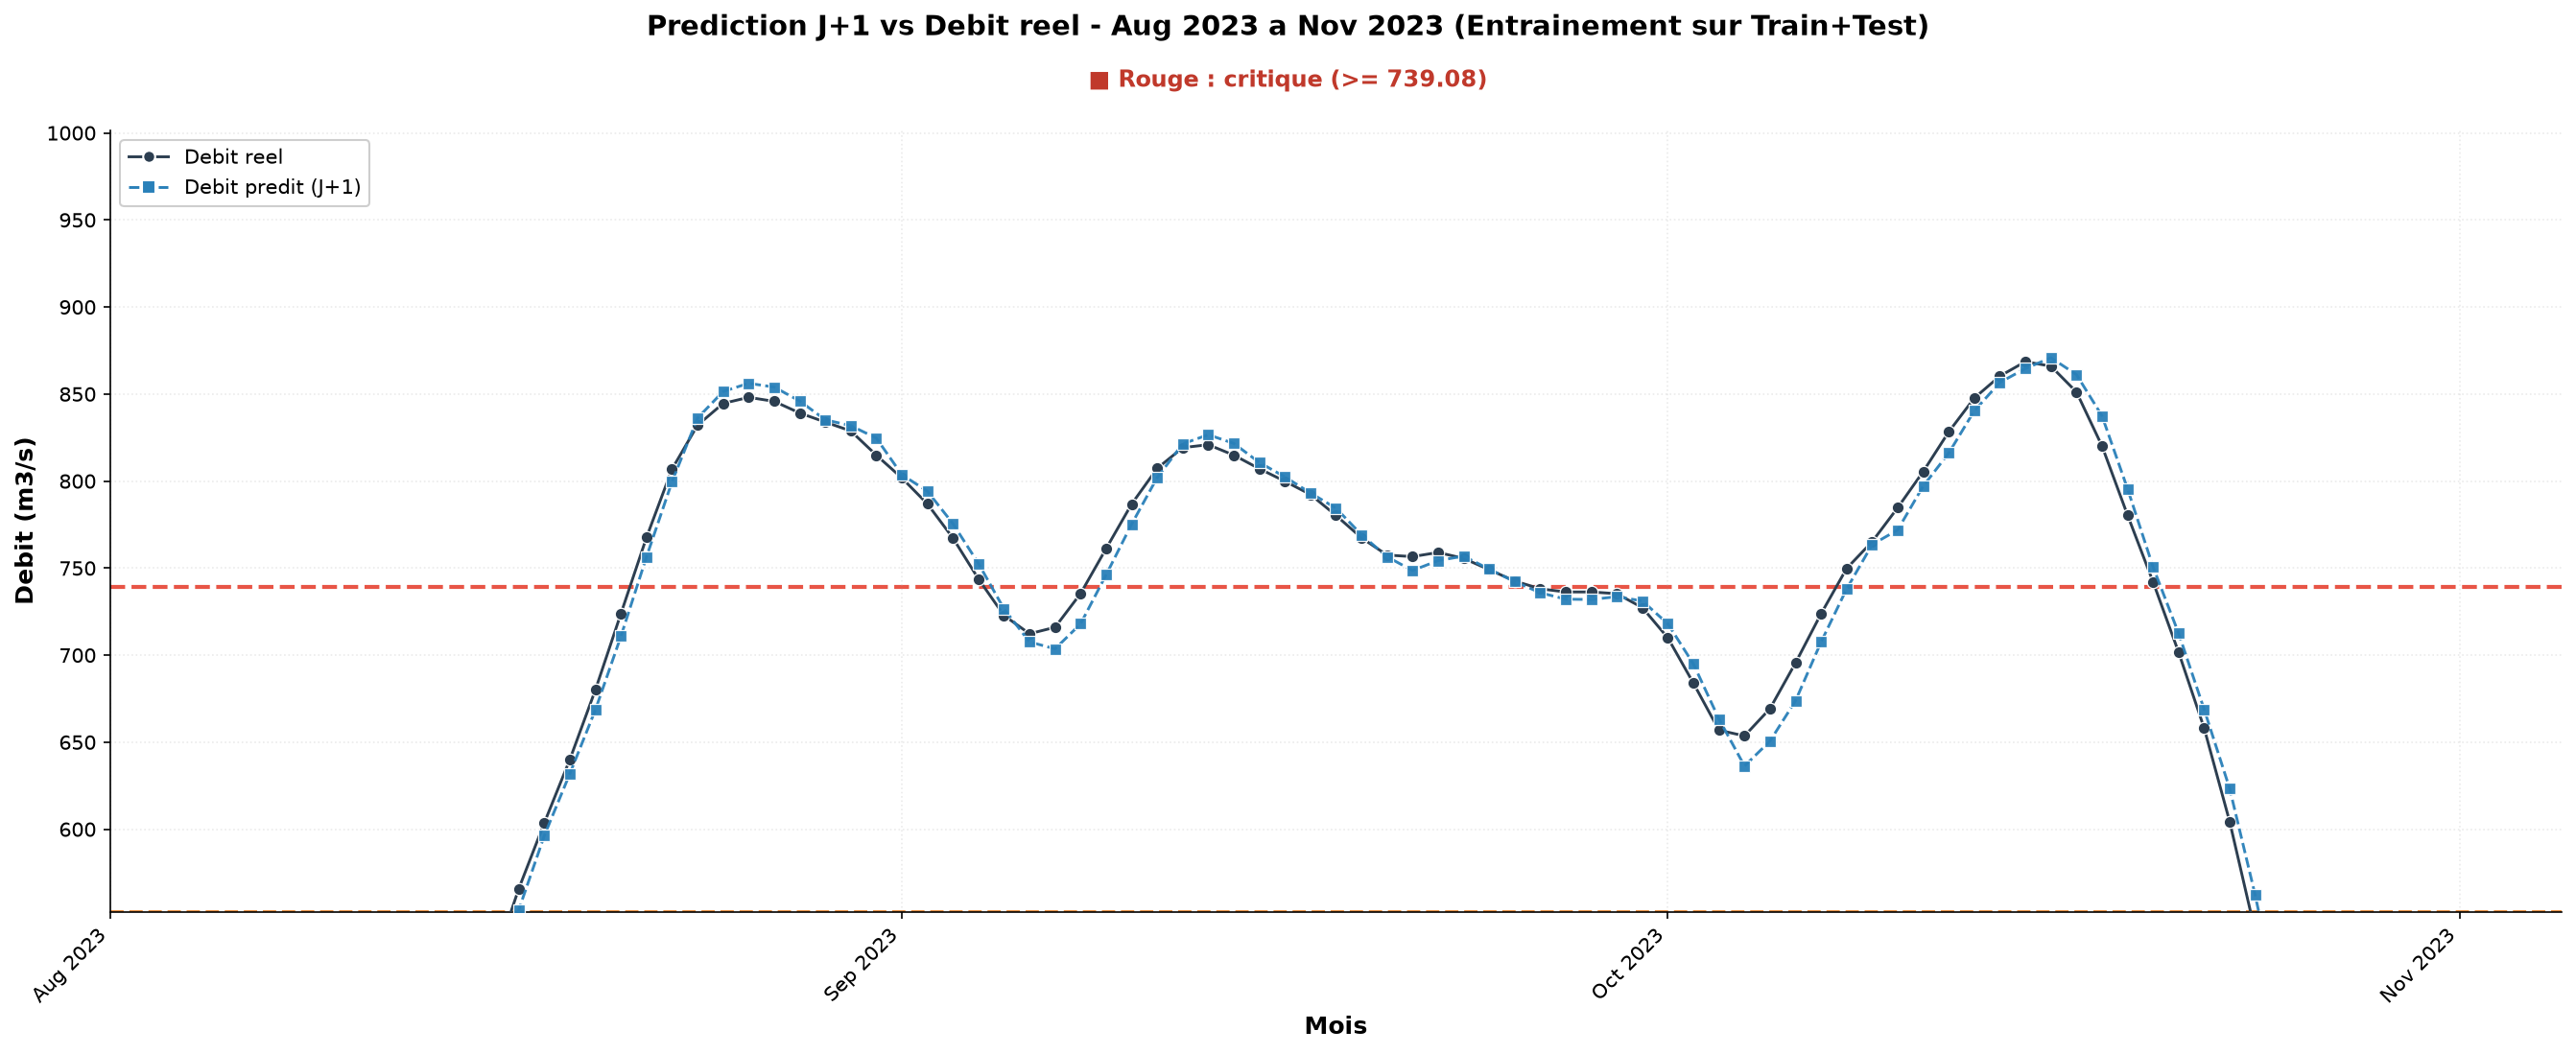

In [218]:
# Graphique : Prediction J+1 vs valeur reelle - zoom sur les zones Orange et Rouge (alerte critique)
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

seuil_vert, seuil_jaune, seuil_orange = 323.96, 552.61, 739.08
y_max_plot = max(y_val["Debit-j+1"].max(), predic_val_j1.max(), seuil_orange) * 1.15

couleur_orange, couleur_rouge = "#e67e22", "#e74c3c"
couleur_orange_txt, couleur_rouge_txt = "#c0611a", "#c0392b"

fig, ax = plt.subplots(figsize=(18, 7), dpi=150)

# Traits horizontaux marquant les seuils (plus de fond colore, juste les traits)
ax.axhline(seuil_jaune, color=couleur_orange, linestyle="--", linewidth=1.8, alpha=0.95, zorder=1)
ax.axhline(seuil_orange, color=couleur_rouge, linestyle="--", linewidth=2, alpha=0.95, zorder=1)

# Courbes reel / predit avec markers espaces (markevery) pour rester lisible sur plusieurs annees
markevery = max(1, len(dates_val) // 150)

ax.plot(dates_val, y_val["Debit-j+1"].values, label="Debit reel",
        color="#2c3e50", linewidth=1.4, marker="o", markersize=6,
        markevery=markevery, markerfacecolor="#2c3e50", markeredgecolor="white",
        markeredgewidth=0.6, zorder=3)
ax.plot(dates_val, predic_val_j1, label="Debit predit (J+1)",
        color="#2980b9", linewidth=1.4, linestyle="--", marker="s", markersize=6,
        markevery=markevery, markerfacecolor="#2980b9", markeredgecolor="white",
        markeredgewidth=0.6, alpha=0.95, zorder=4)

# Axe des x en mois, adapte automatiquement a l'etendue de la periode de validation
n_mois = (dates_val.max().to_period("M") - dates_val.min().to_period("M")).n + 1
interval = max(1, n_mois // 24)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=interval))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax.set_xlabel("Mois", fontsize=12, fontweight='bold')
ax.set_ylabel("Debit (m3/s)", fontsize=12, fontweight='bold')

# Titre principal
fig.suptitle(
    f"Prediction J+1 vs Debit reel - {dates_val.min().strftime('%b %Y')} a {dates_val.max().strftime('%b %Y')} (Entrainement sur Train+Test)",
    fontsize=14, fontweight='bold', y=1.04
)
# Legende des niveaux d'alerte integree juste sous le titre, en couleur

fig.text(0.5, 0.985, "■ Rouge : critique (>= 739.08)", fontsize=11.5, fontweight='bold',
         ha='center', va='top', transform=fig.transFigure, color=couleur_rouge_txt)

# On ne montre que le haut de la figure : zones orange et rouge (on coupe le vert/jaune)
ax.set_xlim(dates_val.min(), dates_val.max())
ax.set_ylim(seuil_jaune, y_max_plot)
ax.grid(True, alpha=0.25, linestyle=':')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# Legende (courbes uniquement, les niveaux d'alerte sont dans le titre)
legend_handles = [
    Line2D([0], [0], color="#2c3e50", linewidth=1.4, marker="o", markersize=6,
           markerfacecolor="#2c3e50", markeredgecolor="white", label="Debit reel"),
    Line2D([0], [0], color="#2980b9", linewidth=1.4, linestyle="--", marker="s", markersize=7,
           markerfacecolor="#2980b9", markeredgecolor="white", label="Debit predit (J+1)"),
]
ax.legend(handles=legend_handles, loc='upper left', frameon=True, fontsize=10, framealpha=0.95)

plt.tight_layout()
plt.show()


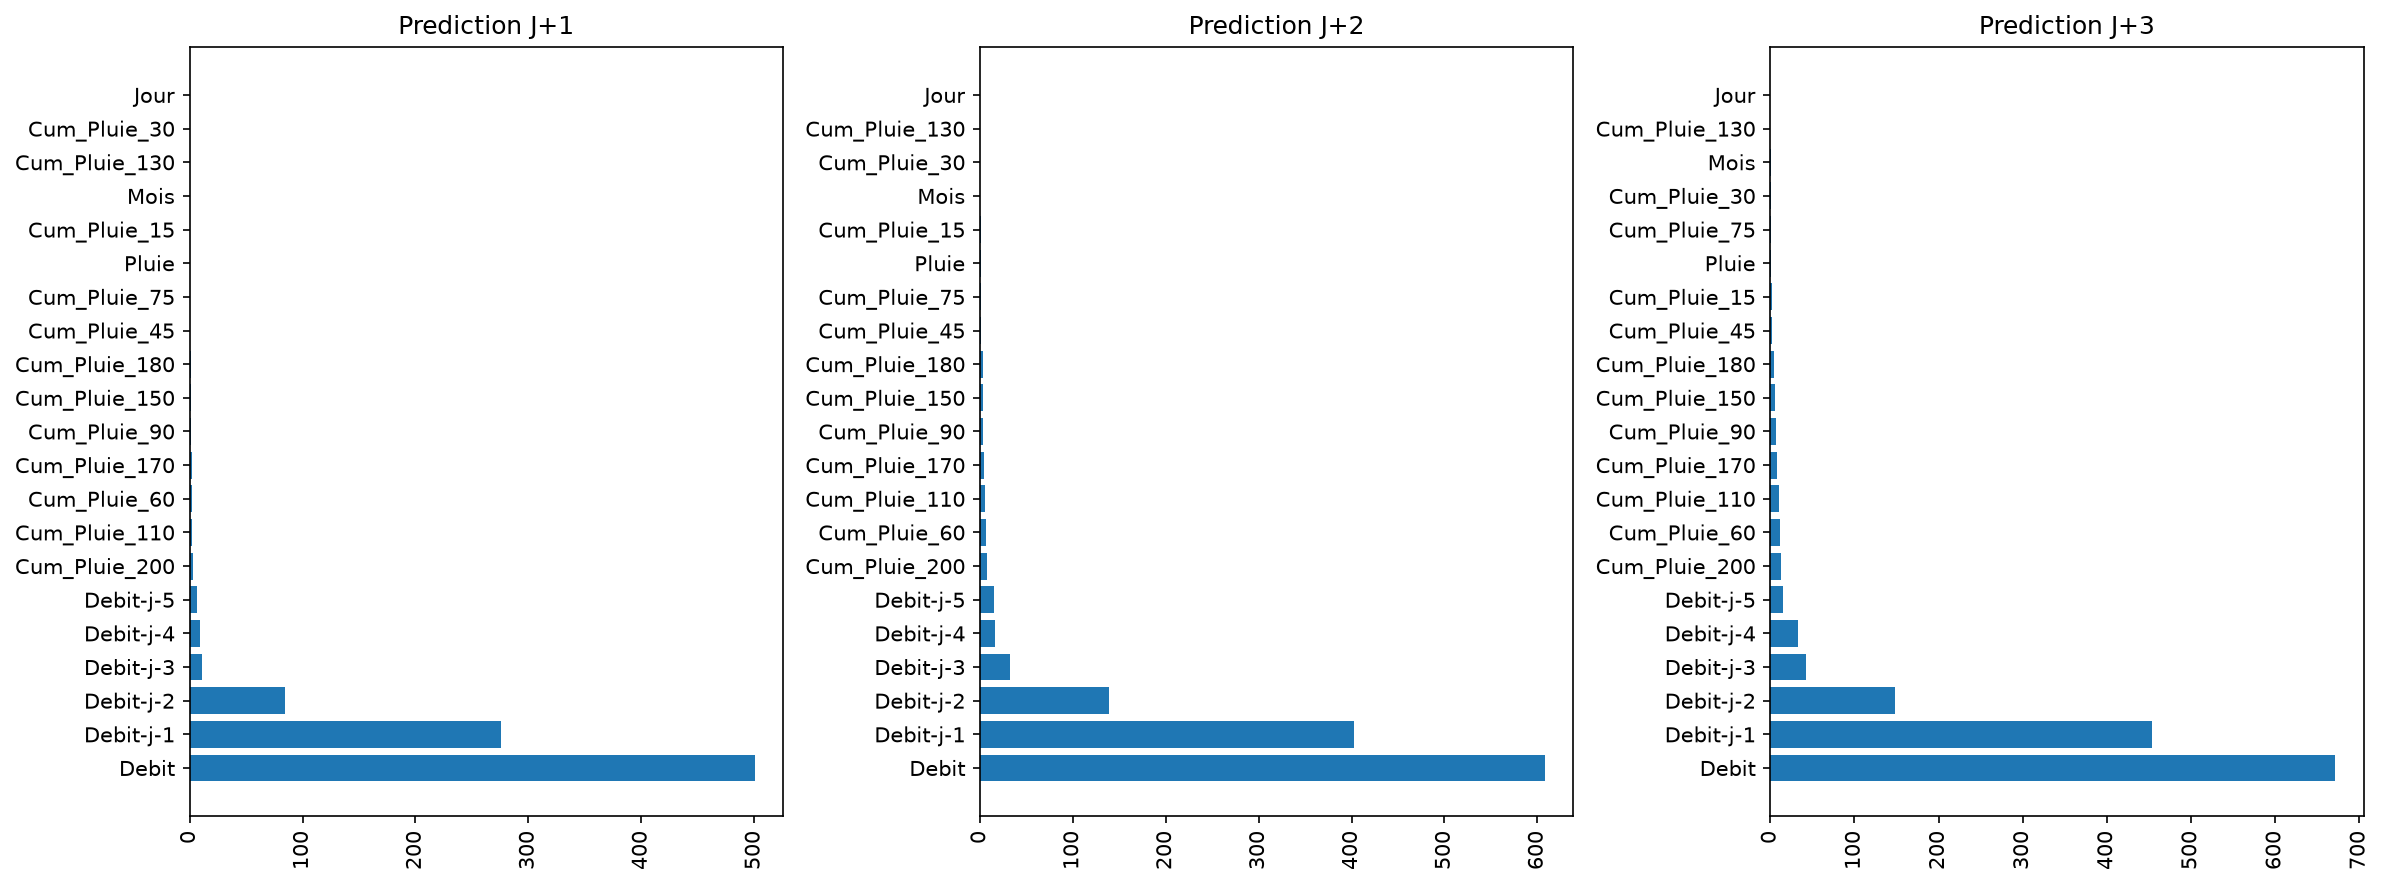

In [216]:
fig,axes=plt.subplots(1,3,figsize=(16,6),dpi=150)
don=pd.DataFrame({"Variable":X_train.columns,"Coefficient (avec abs)":np.abs(model1.coef_)}).sort_values(by="Coefficient (avec abs)",ascending=False)
axes[0].barh(don["Variable"],don["Coefficient (avec abs)"])
axes[0].set_title("Prediction J+1")

don=pd.DataFrame({"Variable":X_train.columns,"Coefficient (avec abs)":np.abs(model2.coef_)}).sort_values(by="Coefficient (avec abs)",ascending=False)
axes[1].barh(don["Variable"],don["Coefficient (avec abs)"])
axes[1].set_title("Prediction J+2")
plt.xticks(rotation=90)
don=pd.DataFrame({"Variable":X_train.columns,"Coefficient (avec abs)":np.abs(model3.coef_)}).sort_values(by="Coefficient (avec abs)",ascending=False)
axes[2].barh(don["Variable"],don["Coefficient (avec abs)"])
axes[2].set_title("Prediction J+3")
for ax in axes:
    ax.tick_params(axis='x', labelrotation=90)
    ax.set_xlim()
plt.tight_layout()
plt.show();